# DASC8412 Assignment 2: Question 6


**Student Number:** ST10365068


### Approach

Data visualisation uses charts, graphs and maps to present information clearly, so that trends and patterns are easier to see and decisions can be made faster (GeeksforGeeks, 2026c). The right chart depends on the type of variable being shown. This notebook first identifies the type of each variable, then summarises the data with statistics suited to each type, then creates the most appropriate charts. Finally, two of the less appropriate charts are drawn to show how a poor choice can hide or misrepresent the patterns in this dataset.

The data is cleaned first using the same steps as Question 5, because summaries and charts built on dirty data would be misleading.

## 1. Import Libraries

In [1]:
# ST10365068
import csv
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Libraries

This code block imports the libraries used in the notebook. pandas is used to clean and summarise the data, and matplotlib and seaborn are used to create the charts.

## 2. Load and Clean the Data

The cleaning steps below are the same as in Question 5. They are combined into one code block here because the focus of this question is summarising and visualising the data.

In [2]:
# ST10365068
# load the file and fix the structural errors
with open('School_Data_CSV.csv', encoding='latin-1') as f:
    raw_lines = f.read().splitlines()

header = raw_lines[0].rstrip(';').split(',')
rows = []
for line in raw_lines[1:]:
    line = line.rstrip(';')
    if line.startswith('"') and line.endswith('"'):
        line = line[1:-1].replace('""', '"')
    rows.append(next(csv.reader([line])))

df = pd.DataFrame([r for r in rows if len(r) == len(header)], columns=header)

# remove extra spaces and replace placeholder labels with missing values
for col in df.columns:
    df[col] = df[col].str.strip()
placeholders = ['NA', 'N/A', 'NOT APPLICABLE', 'TO BE UPDATED', 'To be updated',
                'NULL', 'UNKNOWN', 'TBU', '.', '']
df = df.replace(placeholders, np.nan)

# keep valid EMIS numbers only
df = df[df['emisno'].str.isdigit() & (df['emisno'].str.len() == 9)]

# standardise the quintile column
df['quintile'] = df['quintile'].str.upper().str.replace('NQ', '').str.replace('Q', '')
df.loc[~df['quintile'].isin(['1', '2', '3', '4', '5']), 'quintile'] = np.nan
df['quintile'] = pd.to_numeric(df['quintile']).astype('Int64')

# validate the coordinates and ward codes
df['new_long'] = pd.to_numeric(df['new_long'], errors='coerce')
df['new_lat'] = pd.to_numeric(df['new_lat'], errors='coerce')
inside_sa = df['new_long'].between(16, 33) & df['new_lat'].between(-35, -22)
df.loc[~inside_sa, ['new_long', 'new_lat']] = np.nan
df.loc[~(df['ward_id'].str.isdigit() & (df['ward_id'].str.len() == 8)), 'ward_id'] = np.nan

# combine the name columns and keep one row per school
df['school_name'] = df['institution_name'].fillna(df['centername'])
df = df.drop(columns=['centername', 'institution_name']).drop_duplicates()
df['filled_columns'] = df.notnull().sum(axis=1)
df = df.sort_values('filled_columns', ascending=False).drop_duplicates(subset='emisno')
df = df.drop(columns=['filled_columns']).reset_index(drop=True)

print('Shape of the cleaned dataset:', df.shape)
df.head()

Shape of the cleaned dataset: (33053, 8)


,emisno,centreno,quintile,ward_id,street_address,new_long,new_lat,school_name
0,200100308,4221025,3,29300031,"THIRD AVENUE, HILLSIDE, PORT ELIZABETH 6059",25.54010,-33.89978,HILLSIDE TECHNICAL HIGH SCHOOL
1,200100033,4221026,4,29300007,"ARAGONWEG, ADCOCKVALE, PORT ELIZABETH, 6001",25.58175,-33.94302,ANDREW RABIE HIGH SCHOOL
2,200100300,4211005,3,21004014,"ZOTE STREET, KWANONZWAKAZI LOCATION, ALICEDALE...",26.09900,-33.32026,HENDRIK KANISE COMBINED SCHOOL
3,200100291,4231004,3,21008009,"PATENSIE ROAD, OU HANKEY, HANKEY, 6350",24.87527,-33.83223,HANKEY SENIOR SECONDARY SCHOOL
4,200100357,4231009,3,29300049,"ROSEDALE DRIVE, ROSEDALE, UITENHAGE PO...",25.37949,-33.73471,JOHN WALTON SECONDARY SCHOOL


### Cleaned Dataset

This code block repeats the cleaning process from Question 5. It fixes the file structure, replaces placeholder labels with missing values, removes invalid EMIS numbers, standardises the quintile, validates the coordinates and ward codes, and keeps one row for each school. The cleaned dataset has 33,053 schools, which matches the result in Question 5.

## 3. Add a Province Column

The dataset has no province column, but the province is needed to compare regions as FEDSAS does in the case study. In South Africa the first digit of a ward code identifies the province. The next code block creates a province column from this digit and checks it against the school addresses.

In [3]:
# ST10365068
province_codes = {'1': 'Western Cape', '2': 'Eastern Cape', '3': 'Northern Cape',
                  '4': 'Free State', '5': 'KwaZulu Natal', '6': 'North West',
                  '7': 'Gauteng', '8': 'Mpumalanga', '9': 'Limpopo'}

df['province'] = df['ward_id'].str[0].map(province_codes)

# check the mapping by showing one address from each province
df.dropna(subset=['province', 'street_address']).groupby('province').first()[['ward_id', 'street_address']]

,ward_id,street_address
province,,
Eastern Cape,29300031,"THIRD AVENUE, HILLSIDE, PORT ELIZABETH 6059"
Free State,41904004,"ABERFELDY STREET,WILGEPARK,HARRISMITH,9880"
Gauteng,79900019,"2660, NTSAKO, SLOVOVILLE, WINTERVELDT, PRETORIA"
KwaZulu Natal,52502030,"1398 OSIZWENI,NEWCASTLE,2952"
Limpopo,93505021,GA-MPHAHLELE; PATOGA;
Mpumalanga,83205003,"100 STAND,CALCUTTATRUST,CALCUTTA TRUST,CALCUT..."
North West,64002015,"KRUISSTRAAT 39, , POTCHEFSTROOM, 6747"
Northern Cape,34502009,"MARUPING VILLAGE,MARUPING VILLAGE,MOTHIBISTAD,..."
Western Cape,19100024,"Koppiesdamstraat, Bishop Lavis"


### Province Check

This code block takes the first digit of each ward code and maps it to a province name. The table shows one address for each province as a check. For example, the Western Cape row shows an address in Bishop Lavis in Cape Town, the Gauteng row shows an address in Pretoria and the KwaZulu Natal row shows an address in Newcastle. This confirms that the mapping is correct. Schools without a valid ward code have no province.

## 4. Identify the Variable Types

Before choosing summaries or charts, each variable must be classified, because different types of variables need different summaries and charts (GeeksforGeeks, 2026d).

In [4]:
# ST10365068
variable_types = pd.DataFrame({
    'Variable': ['emisno', 'school_name', 'street_address', 'quintile', 'province', 'ward_id',
                 'new_long', 'new_lat', 'schools per ward (calculated)'],
    'Type': ['Identifier', 'Text', 'Text', 'Categorical (ordinal)', 'Categorical (nominal)',
             'Categorical (nominal)', 'Numerical (continuous)', 'Numerical (continuous)',
             'Numerical (discrete count)'],
    'Use in analysis': ['Counting unique schools', 'Labels only', 'Labels only',
                        'Poverty level of the school community', 'Regional comparison',
                        'Local comparison of school supply', 'Location on a map',
                        'Location on a map', 'How many schools serve each ward'],
})
variable_types

,Variable,Type,Use in analysis
0,emisno,Identifier,Counting unique schools
1,school_name,Text,Labels only
2,street_address,Text,Labels only
3,quintile,Categorical (ordinal),Poverty level of the school community
4,province,Categorical (nominal),Regional comparison
5,ward_id,Categorical (nominal),Local comparison of school supply
6,new_long,Numerical (continuous),Location on a map
7,new_lat,Numerical (continuous),Location on a map
8,schools per ward (calculated),Numerical (discrete count),How many schools serve each ward


### Variable Types

This table classifies every variable. The dataset is mostly categorical. Quintile is ordinal, because quintile 1 is poorer than quintile 5, so its categories have a natural order. Province and ward are nominal categories with no order. The only true numerical variables are the two coordinates, which describe location. There are no date or time variables. A new numerical variable, the number of schools per ward, can be calculated by counting schools in each ward. This classification is what drives every chart choice that follows.

## 5. Summarise the Data

Categorical variables are summarised with counts and percentages, and numerical variables are summarised with measures of centre and spread.

In [5]:
# ST10365068
quintile_summary = pd.DataFrame({
    'Number of schools': df['quintile'].value_counts().sort_index(),
    'Percent of schools with a quintile': (df['quintile'].value_counts(normalize=True).sort_index() * 100).round(1),
})
print('Schools with no quintile:', df['quintile'].isna().sum())
quintile_summary

Schools with no quintile: 8118


,Number of schools,Percent of schools with a quintile
quintile,,
1,8666,34.8
2,7028,28.2
3,5476,22.0
4,1754,7.0
5,2011,8.1


### Quintile Summary

This code block counts the schools in each quintile and shows each count as a percentage. Quintiles 1, 2 and 3, which are the poorer no fee quintiles, make up the large majority of schools. Quintiles 4 and 5 are much smaller groups. This shows that most South African public schools serve poorer communities, which matches the funding pressures discussed in the case study.

In [6]:
# ST10365068
province_summary = df['province'].value_counts().to_frame('Number of schools')
province_summary['Percent'] = (province_summary['Number of schools'] / province_summary['Number of schools'].sum() * 100).round(1)
province_summary

,Number of schools,Percent
province,,
KwaZulu Natal,6348,23.1
Eastern Cape,5840,21.3
Limpopo,4073,14.8
Gauteng,3136,11.4
Western Cape,2202,8.0
Mpumalanga,1943,7.1
Free State,1693,6.2
North West,1688,6.1
Northern Cape,558,2.0


### Province Summary

This code block counts the number of schools in each province. KwaZulu Natal, the Eastern Cape and Limpopo have the most schools, while Gauteng has far fewer schools than KwaZulu Natal or the Eastern Cape, even though it has gained the most learners of any province since 2009. This supports the FEDSAS finding that Gauteng schools are very large, averaging about 1,100 learners each (FEDSAS, 2024), because a large learner population is spread across relatively few schools.

In [7]:
# ST10365068
crosstab = pd.crosstab(df['province'], df['quintile'], normalize='index').round(3) * 100
crosstab

quintile,1,2,3,4,5
province,,,,,
Eastern Cape,35.5,29.9,30.8,1.5,2.3
Free State,56.3,15.0,15.6,5.8,7.3
Gauteng,13.7,12.1,27.9,20.9,25.4
KwaZulu Natal,34.2,29.9,21.0,7.8,7.2
Limpopo,40.3,41.5,15.8,0.6,1.7
Mpumalanga,50.8,32.5,8.2,4.2,4.3
North West,37.3,20.7,33.3,7.8,0.7
Northern Cape,30.6,22.4,22.4,12.5,12.1
Western Cape,17.5,21.4,11.9,19.4,29.9


### Province by Quintile

This code block creates a cross tabulation showing what percentage of each province's schools fall into each quintile. This reveals the relationship between two categorical variables. Provinces such as Limpopo and the Eastern Cape have most of their schools in quintiles 1 and 2, while the Western Cape and Gauteng have a much larger share in quintiles 4 and 5.

In [8]:
# ST10365068
schools_per_ward = df.dropna(subset=['ward_id']).groupby('ward_id').size()

print('Summary of the number of schools per ward:')
print(schools_per_ward.describe().round(2))
print()
print('Median:', schools_per_ward.median())
print('Skewness:', round(schools_per_ward.skew(), 2))

Summary of the number of schools per ward:
count    4551.00
mean        6.04
std         4.29
min         1.00
25%         3.00
50%         5.00
75%         8.00
max        38.00
dtype: float64

Median: 5.0
Skewness: 1.19


### Schools per Ward Summary

This code block counts the schools in each ward and summarises the counts with the mean, median, standard deviation, minimum, maximum and skewness. A typical ward has around five or six schools, but the maximum is much higher and the skewness is positive. This means the distribution is right skewed, with most wards having a few schools and a small number of wards having many. Because the data is skewed, the median is a better measure of the typical ward than the mean.

## 6. The Most Appropriate Visualisations

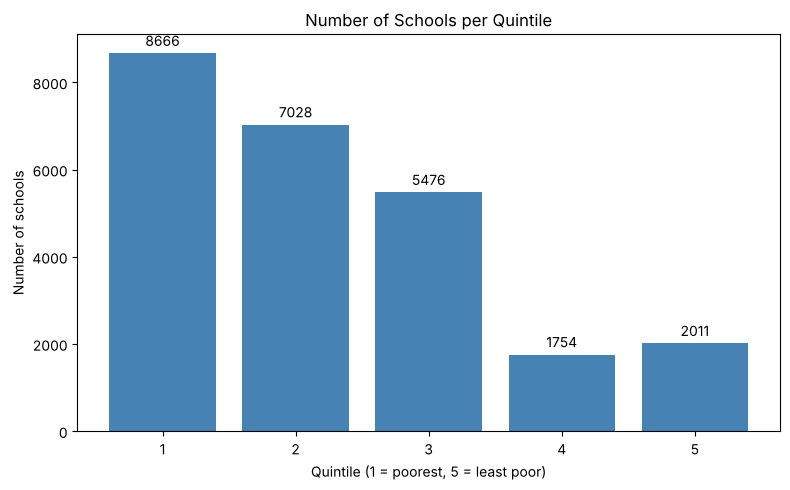

In [9]:
# ST10365068
plt.figure(figsize=(8, 5))
bars = plt.bar(quintile_summary.index.astype(str), quintile_summary['Number of schools'], color='steelblue')
plt.bar_label(bars, padding=3)
plt.title('Number of Schools per Quintile')
plt.xlabel('Quintile (1 = poorest, 5 = least poor)')
plt.ylabel('Number of schools')
plt.tight_layout()
plt.show()

### Bar Chart of Quintiles

A bar chart is the best choice for comparing the number of schools in each quintile, because quintile is a categorical variable and bar charts are designed for comparing values across categories (GeeksforGeeks, 2026d). The bars are kept in quintile order from 1 to 5, so the ordinal nature of the variable is preserved and the decline from poorer to wealthier quintiles is easy to see.

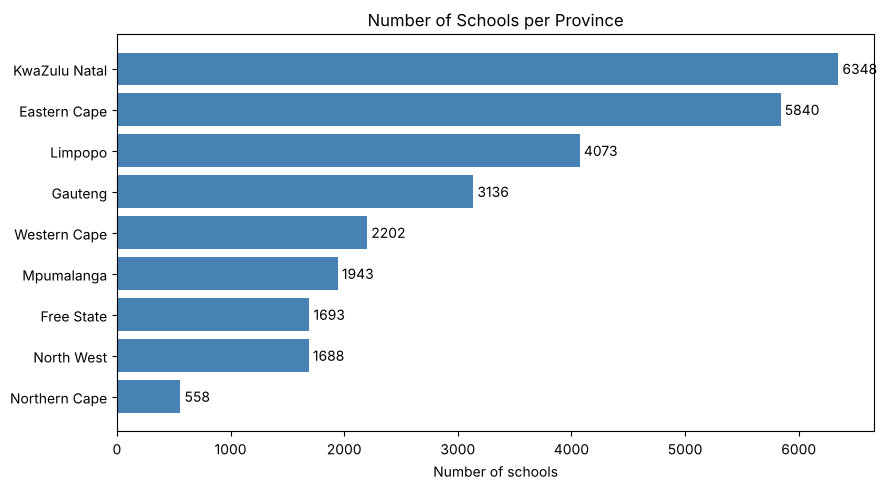

In [10]:
# ST10365068
plt.figure(figsize=(9, 5))
order = province_summary.index
bars = plt.barh(order, province_summary['Number of schools'], color='steelblue')
plt.bar_label(bars, padding=3)
plt.gca().invert_yaxis()
plt.title('Number of Schools per Province')
plt.xlabel('Number of schools')
plt.tight_layout()
plt.show()

### Horizontal Bar Chart of Provinces

A horizontal bar chart, sorted from largest to smallest, is used for the provinces. Province is a nominal variable with nine categories and fairly long names, which fit better on a horizontal axis. Sorting the bars makes it easy to rank the provinces and to notice that Gauteng has relatively few schools.

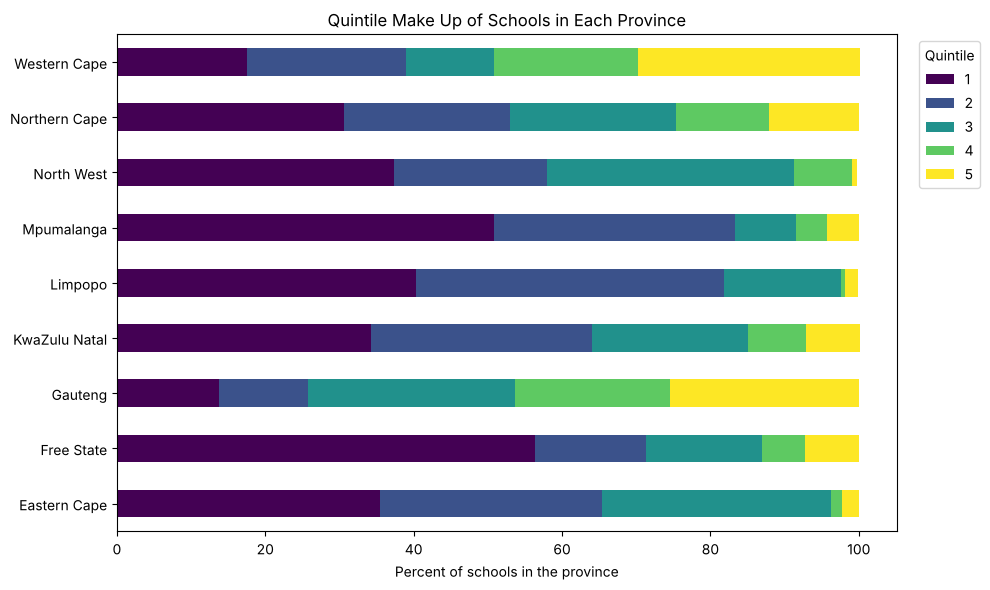

In [11]:
# ST10365068
crosstab.plot(kind='barh', stacked=True, figsize=(10, 6), colormap='viridis')
plt.title('Quintile Make Up of Schools in Each Province')
plt.xlabel('Percent of schools in the province')
plt.ylabel('')
plt.legend(title='Quintile', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Stacked Bar Chart of Province by Quintile

A 100% stacked bar chart shows how each province's schools are divided across the quintiles. Stacked bars are suited to showing how parts contribute to a whole when there are only a few categories (GeeksforGeeks, 2025g). Because each bar adds up to 100%, provinces of very different sizes can be compared fairly. The chart shows the relationship between province and poverty level clearly, with the Western Cape and Gauteng having a much larger share of quintile 4 and 5 schools.

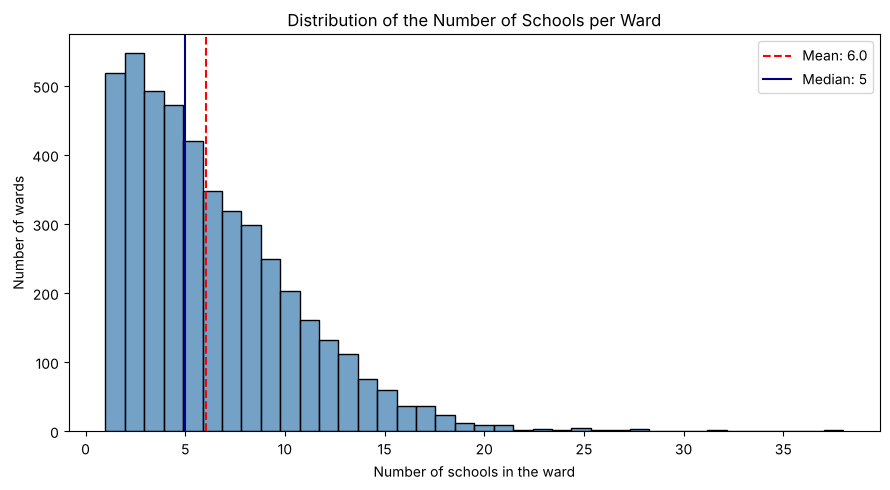

In [12]:
# ST10365068
plt.figure(figsize=(9, 5))
sns.histplot(schools_per_ward, bins=38, color='steelblue')
plt.axvline(schools_per_ward.mean(), color='red', linestyle='--', label=f'Mean: {schools_per_ward.mean():.1f}')
plt.axvline(schools_per_ward.median(), color='navy', label=f'Median: {schools_per_ward.median():.0f}')
plt.title('Distribution of the Number of Schools per Ward')
plt.xlabel('Number of schools in the ward')
plt.ylabel('Number of wards')
plt.legend()
plt.tight_layout()
plt.show()

### Histogram of Schools per Ward

A histogram is the best choice for the number of schools per ward, because this is a numerical variable and a histogram shows the shape, spread and outliers of a distribution (GeeksforGeeks, 2026d). The chart confirms the right skew found in the summary, with the mean line sitting to the right of the median. Wards in the far left of the chart, with only one or two schools, are the ones that may need further investigation for overcrowding.

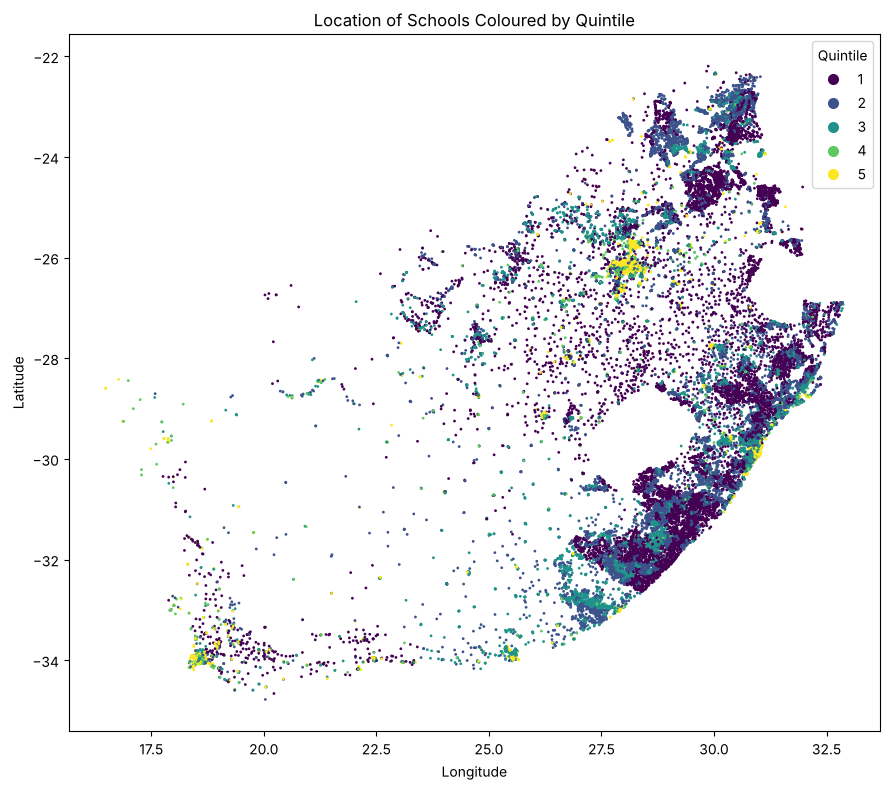

In [13]:
# ST10365068
map_df = df.dropna(subset=['new_long', 'new_lat', 'quintile'])

plt.figure(figsize=(9, 8))
sns.scatterplot(data=map_df, x='new_long', y='new_lat', hue='quintile', palette='viridis', s=4, linewidth=0)
plt.title('Location of Schools Coloured by Quintile')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend(title='Quintile', markerscale=4)
plt.tight_layout()
plt.show()

### Scatter Plot Map by Quintile

A scatter plot of longitude against latitude acts as a map, because both coordinates are continuous numerical variables. Colouring each point by quintile adds a third variable, so the chart shows both where schools are and what kind of community they serve. Map visuals are suited to showing geographic patterns (GeeksforGeeks, 2025g). The map shows that poorer quintile 1 and 2 schools are concentrated in the rural east, while quintile 4 and 5 schools cluster in the cities, such as Cape Town and Gauteng.

## 7. Examples of Less Appropriate Visualisations

The following two charts are drawn on purpose to show how a poor chart choice can hide or misrepresent the data.

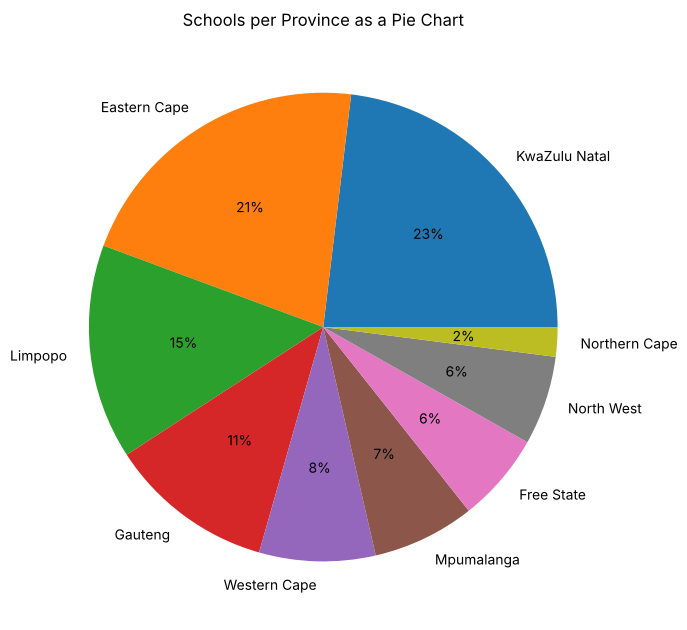

In [14]:
# ST10365068
plt.figure(figsize=(7, 7))
plt.pie(province_summary['Number of schools'], labels=province_summary.index, autopct='%1.0f%%')
plt.title('Schools per Province as a Pie Chart')
plt.tight_layout()
plt.show()

### Pie Chart Example

This pie chart shows the same province counts as the horizontal bar chart. With nine slices, several slices are similar in size, and it is very hard to rank provinces such as Mpumalanga, the Free State and North West by eye. A pie chart also cannot show the province by quintile relationship without drawing nine separate pies. The bar chart presents the same information far more clearly.

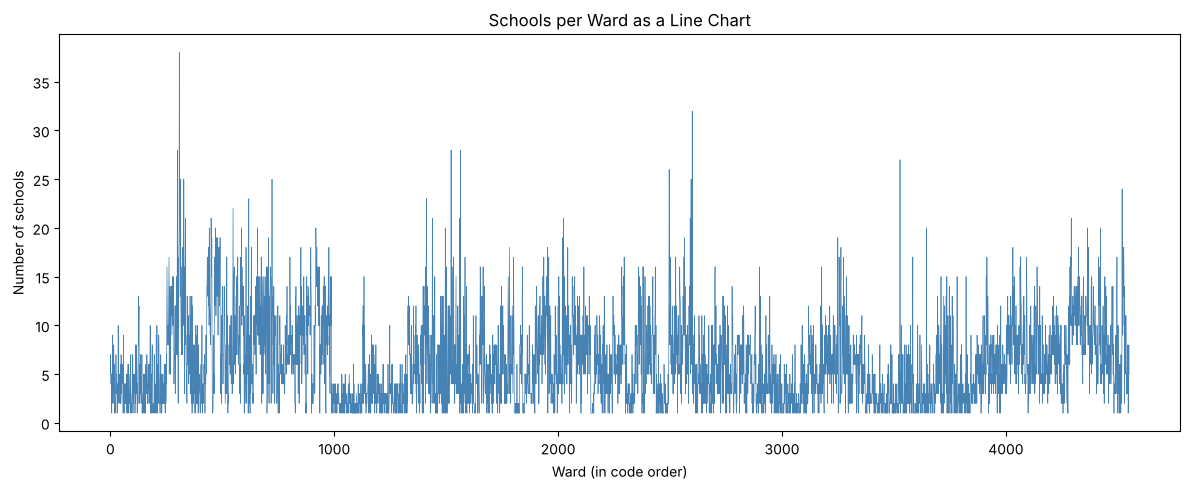

In [15]:
# ST10365068
plt.figure(figsize=(12, 5))
plt.plot(schools_per_ward.values, color='steelblue', linewidth=0.5)
plt.title('Schools per Ward as a Line Chart')
plt.xlabel('Ward (in code order)')
plt.ylabel('Number of schools')
plt.tight_layout()
plt.show()

### Line Chart Example

This line chart plots the number of schools in each ward in ward code order. Line charts are meant to show change over an ordered scale, usually time (GeeksforGeeks, 2026d). Wards are nominal categories with no natural order, so the line suggests a trend from one ward to the next that does not exist. With more than 4,500 wards, the result is also an unreadable band of noise that hides the distribution. The histogram shows the same data in a far more meaningful way.

## References

Combrink, H., Carr, E., de Wet, K., Marivate, V. and Rosman, B. (2023) *South Africa Education Data and Visualisations*. University of the Free State. Available at: https://doi.org/10.38140/ufs.22081058.v4 [Accessed 14 October 2026].

FEDSAS (2024) *FEDSAS's 'Education in numbers' report: These are some of the most important tendencies in SA education*. Federation of Governing Bodies of South African Schools, 4 December. Available at: https://www.fedsas.org.za/Media/Article/fedsas-s-education-in-numbers-report-these-are-some-of-the-most-important-tendencies-in-sa-education-202412041111 [Accessed 14 October 2026].

GeeksforGeeks (2025g) *12 Useful ways to visualize your data (with examples)*. Available at: https://www.geeksforgeeks.org/data-visualization/12-useful-ways-to-visualize-your-data-with-examples/ [Accessed 14 October 2026].

GeeksforGeeks (2026c) *Introduction to data visualization*. Available at: https://www.geeksforgeeks.org/data-visualization/data-visualization-and-its-importance/ [Accessed 14 October 2026].

GeeksforGeeks (2026d) *Types of Data Visualization Charts: From Basic to Advanced*. Available at: https://www.geeksforgeeks.org/data-analysis/types-of-data-visualization/ [Accessed 14 October 2026].